In [3]:
!pip install statsmodels

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 1.6 MB/s eta 0:00:00m eta 0:00:010:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.9/118.9 kB 635.5 kB/s eta 0:00:0031m1.9 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 233.3/233.3 kB 1.0 MB/s eta 0:00:003.2 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 250.6/250.6 kB 1.6 MB/s eta 0:00:000:00:01m eta 0:00:01


In [4]:
import pandas as pd
import numpy as np

dates = pd.date_range(start='2023-01-01', periods=100)

prices = np.linspace(100, 150, 100) + np.random.normal(0, 3, 100) 
volumes = np.random.randint(1000, 5000, 100)

mock_stock = pd.DataFrame({'Date': dates, 'Close_Price': prices, 'Volume': volumes})
mock_stock.to_csv('Stock_Prices.csv', index=False)

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Date         100 non-null    str    
 1   Close_Price  100 non-null    float64
 2   Volume       100 non-null    int64  
dtypes: float64(1), int64(1), str(1)
memory usage: 2.5 KB
Data info:
 None


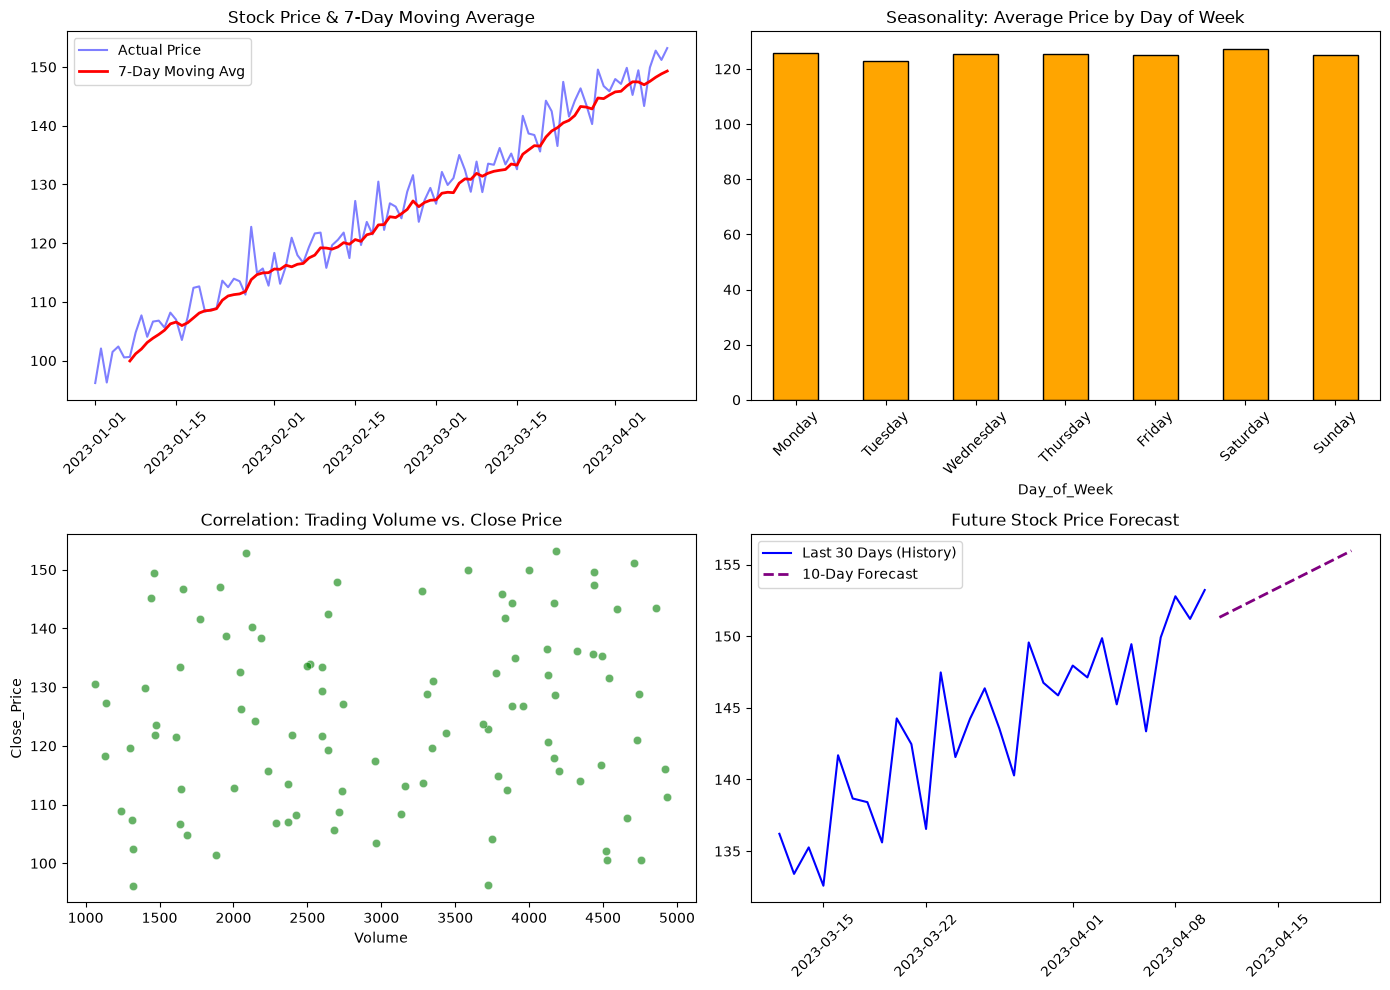

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.holtwinters import ExponentialSmoothing

df = pd.read_csv('Stock_Prices.csv')
print("Data info:\n", df.info())

df['Date'] = pd.to_datetime(df['Date'])
df = df.set_index('Date') 
df.index.freq = 'D'       

df['7_Day_MA'] = df['Close_Price'].rolling(window=7).mean()

model = ExponentialSmoothing(df['Close_Price'], trend='add', seasonal=None)
fit_model = model.fit()

forecast = fit_model.forecast(steps=10)

plt.figure(figsize=(14, 10))

plt.subplot(2, 2, 1)
plt.plot(df.index, df['Close_Price'], label='Actual Price', color='blue', alpha=0.5)
plt.plot(df.index, df['7_Day_MA'], label='7-Day Moving Avg', color='red', linewidth=2)
plt.title('Stock Price & 7-Day Moving Average')
plt.xticks(rotation=45)
plt.legend()

plt.subplot(2, 2, 2)
df['Day_of_Week'] = df.index.day_name()

day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
seasonality = df.groupby('Day_of_Week')['Close_Price'].mean().reindex(day_order)
seasonality.plot(kind='bar', color='orange', edgecolor='black')
plt.title('Seasonality: Average Price by Day of Week')
plt.xticks(rotation=45)

plt.subplot(2, 2, 3)
sns.scatterplot(x='Volume', y='Close_Price', data=df, color='green', alpha=0.6)
plt.title('Correlation: Trading Volume vs. Close Price')

plt.subplot(2, 2, 4)
plt.plot(df.index[-30:], df['Close_Price'][-30:], label='Last 30 Days (History)', color='blue')

plt.plot(forecast.index, forecast, label='10-Day Forecast', color='purple', linestyle='--', linewidth=2)
plt.title('Future Stock Price Forecast')
plt.xticks(rotation=45)
plt.legend()

plt.tight_layout()
plt.show()